In [1]:
%load_ext autoreload
%autoreload 2

# Variance reduction



The price was defined as the discounted expectation. With a Monte Carlo approach to the sampling, the standard error is

      std_err = sigma_payoff / sqrt(N)

Two levers follow, and no others.
- N: brute force approach, costly because of the square root: one more digit of
  accuracy needs a hundred times the samples.
- Lowering sigma_payoff: variance reduction techniques (investigated in this notebook).

A variance reduction technique must not change the price, only its spread. An
estimator that respects this requirement is called unbiased. Therefore every
technique is tested against a plain Monte Carlo run.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from mcpricer import analytical, estimators, models, payoffs

%matplotlib inline
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110

S0, K, r, y, sigma, tau = 100.0, 100.0, 0.05, 0.0, 0.20, 1.0
rng = np.random.default_rng(42)

call = dict(payoff_fn=payoffs.call_payoff, model_fn=models.terminal_price,
            S0=S0, K=K, r=r, y=y, sigma=sigma, T=tau)

bs = analytical.black_scholes_call(S0, K, r, sigma, tau, y=y)
res = estimators.mc_price_european(N=1e6, rng=rng, **call)

print(f"Black-Scholes  {bs:.6f}")
print(f"plain MC       {res.price:.6f} +/- {res.std_err:.6f}")
print(f"deviation      {(res.price - bs) / res.std_err:+.2f} standard errors")
print(f"R              {res.rel_err:.5f}")
print(f"var_per_eval   {res.var_per_eval:.2f}")
print(f"fom            {res.fom:.3e}   ({res.elapsed * 1e3:.1f} ms)")

Black-Scholes  10.450584
plain MC       10.453195 +/- 0.014731
deviation      +0.18 standard errors
R              0.00141
var_per_eval   217.02
fom            2.161e+07   (23.3 ms)


           N      price   std_err     dev         R  var/eval   t [ms]
----------------------------------------------------------------------
       1,000   10.16160   0.44062  -0.66s   0.04336    194.14      0.1
      10,000   10.49095   0.14833  +0.27s   0.01414    220.02      0.2
     100,000   10.45896   0.04662  +0.18s   0.00446    217.38      1.9
   1,000,000   10.46001   0.01472  +0.64s   0.00141    216.67     18.4
  10,000,000   10.44721   0.00465  -0.73s   0.00045    216.53    250.4

fitted log-log slope  -0.4956   (theory -0.5)
var_per_eval          194.14 to 220.02


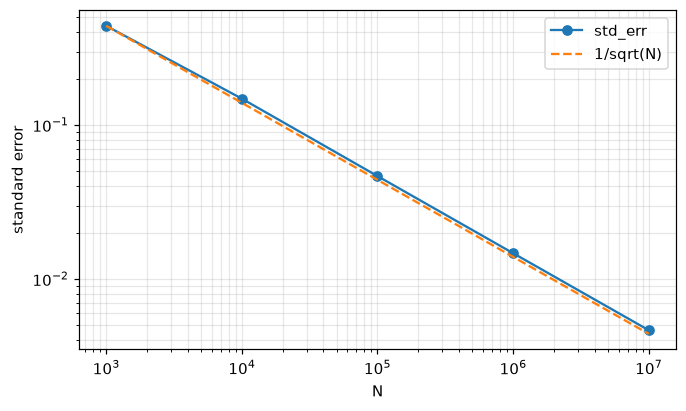

In [3]:
Ns = [10**k for k in range(3, 8)]
runs = [estimators.mc_price_european(N=N, rng=rng, **call) for N in Ns]

print(f"{'N':>12} {'price':>10} {'std_err':>9} {'dev':>7} {'R':>9} {'var/eval':>9} {'t [ms]':>8}")
print("-" * 70)
for run in runs:
    print(f"{run.n_samples:>12,} {run.price:>10.5f} {run.std_err:>9.5f} "
          f"{(run.price - bs) / run.std_err:>+6.2f}s {run.rel_err:>9.5f} "
          f"{run.var_per_eval:>9.2f} {run.elapsed * 1e3:>8.1f}")

errs = np.array([run.std_err for run in runs])

fig, ax = plt.subplots()
ax.loglog(Ns, errs, "o-", label="std_err")
ax.loglog(Ns, errs[0] * np.sqrt(Ns[0] / np.array(Ns, float)), "--", label="1/sqrt(N)")
ax.set_xlabel("N")
ax.set_ylabel("standard error")
ax.legend()
ax.grid(alpha=0.3, which="both")

print(f"\nfitted log-log slope  {np.polyfit(np.log(Ns), np.log(errs), 1)[0]:.4f}   (theory -0.5)")
print(f"var_per_eval          {min(q.var_per_eval for q in runs):.2f} to {max(q.var_per_eval for q in runs):.2f}")

## Comparison of the techniques

Two measures of cost are used.

var_per_eval rescales the variance to one payoff evaluation:

      var_per_eval = var * n_evals / n_samples

It is deterministic and the same on any machine.
The reduction factor of a technique is its var_per_eval against plain MC.

fom is the transport figure of merit, with relative error R = std_err / price:

      fom = 1 / (R^2 * t)

R^2 falls as 1/N while t grows as N, so the product is constant: the fom describes the
method, not the length of the run. It is the cost actually paid, but it is machine-specific and unreliable
at small N, where t is too short to measure. In Monte Carlo for radiation transport, usually one tries to maximize the FOM.
In practice, often a reduction of time increases R, and vice versa. Variance reduction is almost always paid for in time per
history, so the fom is the number that says whether the trade was worth it. This is why e.g.
splitting and Russian roulette are used together: one buys variance by spending time,
the other buys time by spending variance.

## Antithetic variates

Z and -Z have the same distribution, so every draw can be used twice for free. Instead
of N normals, draw N/2 and evaluate the payoff at both +Z and -Z, then average the pair.

The variance of a pair average is

      Var((X+ + X-)/2) = (1/2) * [Var(X) + Cov(X+, X-)]

so the gain comes from the covariance being negative.
That happens when the chain Z -> S_T -> payoff is monotone, which holds for
a call.
With positive covariance the pair would be noisier than two independent draws, so the
technique would lose against plain MC at the same budget.

One sample is now a pair and costs two payoff evaluations, so n_evals is 2 * len(Z)
while n_samples is len(Z). Due to this difference, variance per sample is not
comparable across estimators.

There is no direct counterpart in radiation transport Monte Carlo (MCNP, FLUKA); this is
correlated sampling, not biasing, with no involvement of any weights.

In [4]:
N = 1e6

plain = estimators.mc_price_european(N=N, rng=rng, **call)
anti = estimators.mc_antithetic(N=N, rng=rng, **call)

for name, q in (("plain", plain), ("antithetic", anti)):
    print(f"{name:11} price={q.price:.6f}  dev={(q.price - bs) / q.std_err:+5.2f}s  "
          f"se={q.std_err:.6f}  n_samples={q.n_samples:>9,}  n_evals={q.n_evals:>9,}")

print(f"\nvar per sample    {plain.var / anti.var:6.2f}x   <- not comparable")
print(f"var_per_eval      {plain.var_per_eval:7.2f} -> {anti.var_per_eval:7.2f}")
print(f"reduction factor  {plain.var_per_eval / anti.var_per_eval:6.2f}x   <- budget-fair")
print(f"fom               {plain.fom:.2e} -> {anti.fom:.2e}   ({anti.fom / plain.fom:.2f}x)")
print(f"time              {plain.elapsed * 1e3:.1f} ms -> {anti.elapsed * 1e3:.1f} ms")

plain       price=10.459558  dev=+0.61s  se=0.014745  n_samples=1,000,000  n_evals=1,000,000
antithetic  price=10.437177  dev=-1.29s  se=0.010377  n_samples=  500,000  n_evals=1,000,000

var per sample      4.04x   <- not comparable
var_per_eval       217.42 ->  107.68
reduction factor    2.02x   <- budget-fair
fom               2.56e+07 -> 6.57e+07   (2.57x)
time              19.7 ms -> 15.4 ms


In [5]:
# the mechanism: the two legs must be negatively correlated.
Z = rng.normal(size=500_000)
up = models.terminal_price(Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)
down = models.terminal_price(-Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)
corr = np.corrcoef(payoffs.call_payoff(up, K=K), payoffs.call_payoff(down, K=K))[0, 1]
print(f"corr(+Z, -Z)        {corr:+.4f}")
print(f"predicted var ratio {2 / (1 + corr):.2f}")

corr(+Z, -Z)        -0.5003
predicted var ratio 4.00


## Control variates

X is the discounted payoff of a single draw, exp(-r*tau) * payoff(S_T), and its mean
is the price.
Take a second quantity Y whose mean is known exactly, correlated with X.
For any constant c,

      X_cv = X - c * (Y - E[Y])

Given that E[Y - E[Y]] = E[Y] - E[Y] = 0, X_cv has the same mean as X, for every c.


The variance of X - c*Y is:

      Var(X - c*Y) = Var(X) - 2c*Cov(X,Y) + c^2 * Var(Y)

which is a parabola in c, with minimum at c* = Cov(X,Y) / Var(Y).
Given rho = Cov / sqrt(Var(X)*Var(Y)), at minimum c*, the variance becomes:

      Var(X - c* Y) = Var(X) * (1 - rho^2)

so the reduction factor is 1/(1 - rho^2) and depends on the correlation alone. Outside
the interval (0, 2c*) the corrected estimator is noisier than plain MC, so a badly
chosen coefficient negatively impacts the calculation.

In this work, Y is the discounted terminal price. Other Y would have been possible.
This Y is convenient because of the assumption of risk-neutral measure. By this, it is a
martingale, whose mean is known analytically:

      E[exp(-r*tau) * S_T] = S0 * exp(-y*tau)

This choice carries strong correlation with the call payoff and has the advantage that S_T
is already simulated.
It is also noted that X and Y must come from the same Z to have a correlation of the two.

n_evals stays N, one payoff evaluation per sample, so the cost of this technique is not
in the evaluations but in the covariance computed over the whole array. Only the fom
sees it.

Correlated sampling in radiation transport works on the same mechanism: two quantities
computed on the same random numbers are correlated, and that correlation is what buys the
variance reduction. Correlated sampling lowers the variance of a difference between two runs,
which is why it serves perturbation and sensitivity calculations. The control variates
approach shares a similar idea, but lowers the variance of a single estimate, using a mean
known in advance.

In [6]:
cv = estimators.mc_control_variate(N=N, rng=rng, **call)

for name, q in (("plain", plain), ("antithetic", anti), ("control variate", cv)):
    print(f"{name:16} price={q.price:.6f}  dev={(q.price - bs) / q.std_err:+5.2f}s  "
          f"var_per_eval={q.var_per_eval:7.2f}  gain={plain.var_per_eval / q.var_per_eval:5.2f}x")

print(f"\nfom   {plain.fom:.2e} -> {cv.fom:.2e}   ({cv.fom / plain.fom:.2f}x)")
print(f"time  {plain.elapsed * 1e3:.1f} ms -> {cv.elapsed * 1e3:.1f} ms   (with the same n_evals)")

plain            price=10.459558  dev=+0.61s  var_per_eval= 217.42  gain= 1.00x
antithetic       price=10.437177  dev=-1.29s  var_per_eval= 107.68  gain= 2.02x
control variate  price=10.447620  dev=-0.53s  var_per_eval=  31.48  gain= 6.91x

fom   2.56e+07 -> 1.06e+08   (4.15x)
time  19.7 ms -> 32.7 ms   (with the same n_evals)


In [7]:
# the gain is set by the correlation alone
Z = rng.normal(size=500_000)
S_T = models.terminal_price(Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)

X = np.exp(-r * tau) * payoffs.call_payoff(S_T, K=K)
Y = np.exp(-r * tau) * S_T

rho = np.corrcoef(X, Y)[0, 1]
c_star = np.cov(X, Y, ddof=1)[0, 1] / np.var(Y, ddof=1)

print(f"rho                   {rho:.4f}")
print(f"c*                    {c_star:.4f}")
print(f"predicted 1/(1-rho^2) {1 / (1 - rho**2):.2f}x")
print(f"observed gain         {plain.var_per_eval / cv.var_per_eval:.2f}x")

# passing c skips np.cov, so the time difference is what np.cov costs
cv_pilot = estimators.mc_control_variate(N=N, rng=rng, c=c_star, **call)
print(f"\nestimated c  {cv.elapsed * 1e3:5.1f} ms")
print(f"passed c     {cv_pilot.elapsed * 1e3:5.1f} ms")

rho                   0.9245
c*                    0.6737
predicted 1/(1-rho^2) 6.88x
observed gain         6.91x

estimated c   32.7 ms
passed c      22.3 ms


## Importance sampling
Plain Monte Carlo on a call, varying only the strike. S0 = 100, sigma = 20%, tau = 1.

In [8]:
N_scan = 200_000

for K_scan in (100.0, 150.0, 200.0):
    Z_scan = rng.normal(size=N_scan)
    S_T_scan = models.terminal_price(Z_scan, r=r, T=tau, S0=S0, sigma=sigma, y=y)
    payoff = payoffs.call_payoff(S_T_scan, K=K_scan)

    n_hit = int((payoff > 0).sum())
    price = np.exp(-r * tau) * payoff.mean()
    std_err = np.exp(-r * tau) * payoff.std(ddof=1) / np.sqrt(N_scan)
    exact = analytical.black_scholes_call(S0, K_scan, r, sigma, tau, y=y)

    print(f"K={K_scan:>5.0f}  non-zero payoffs {n_hit:>7,} / {N_scan:,}   "
          f"price {price:.6f} \t exact {exact:.6f} \t rel.err {std_err / price * 100:5.2f}%")

K=  100  non-zero payoffs 111,803 / 200,000   price 10.404191 	 exact 10.450584 	 rel.err  0.31%
K=  150  non-zero payoffs   6,036 / 200,000   price 0.354742 	 exact 0.359630 	 rel.err  1.77%
K=  200  non-zero payoffs      91 / 200,000   price 0.004901 	 exact 0.004799 	 rel.err 15.43%


A call with a high strike pays only on the paths where the stock ends above K. At
K = 200 the stock has to double in a year, which is 3.3 standard deviations of the log
return, so about 100 draws out of 200,000 produce a non-zero payoff. The rest contribute
zero and cost the same.

Precision is then set by the number of hits, not by N: with n non-zero payoffs the
relative error is around 1/sqrt(n). Raising N buys hits at a rate of 5 per 10,000.
With so few hits the variance is itself estimated from that handful of samples, so the error bar is unreliable as well.

This is the rare-event problem of radiation transport: an interaction in a thin target,
or the flux reaching a detector after a maze, where most particles are absorbed in the
walls and the tally is carried by the few that scatter through the bends.

The remedy is the same in both: stop sampling from the natural distribution and concentrate
(bias) where the contributions are, and correct each sample with a weight.

The idea is to introduce a second density g, sample from it instead of the standard normal f, and weight each sample by f/g. Writing X(Z) for the discounted payoff as a function of the draw,
and E_f for an expectation over Z drawn from f,

      E_f[X(Z)] = integral X(z) f(z) dz
                = integral X(z) * [f(z)/g(z)] * g(z) dz
                = E_g[ X(Z) * f(Z)/g(Z) ]

The estimator stays unbiased for any g that covers the support of f. The variance depends on which g is chosen.

The ratio f/g is the particle weight of radiation transport.

The choice of g stays critical for the biasing to be effective. A first heuristic is to ask for a distribution centred roughly where the payoff turns on, S_T = K:

      S0 * exp((r - y - sigma^2/2)*tau + sigma*sqrt(tau)*mu) = K

and solving for mu,

      mu* = [ln(K/S0) - (r - y - sigma^2/2)*tau] / (sigma*sqrt(tau))

This is a heuristic: it cuts the variance by orders of magnitude without being the mu that minimises it. The g that does minimise it is proportional to |X(z)| * f(z), normalised by E[X], the price being computed. That g gives zero variance and cannot be used, since using it requires knowing the answer.

The analogous case is plain in importance biasing for particle transport. The optimal scheme for transport towards a detector is the adjoint flux, unknown for the same reason, since having it means having the answer. Practical schemes either use approximations of it or rest on heuristics and the experience of the analyst.

In [9]:
def mu_star(K_target):
    """Shift that centres the sampling distribution on the strike."""
    return (np.log(K_target / S0) - (r - y - 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))


print(f"{'K':>5} {'exact':>10} {'plain':>10} {'rel.err':>8} {'IS':>10} {'rel.err':>8} {'mu*':>6} {'gain':>9}")
print("-" * 76)

for K_is in (100.0, 125.0, 150.0, 175.0, 200.0):
    call_is = dict(call, K=K_is)
    exact = analytical.black_scholes_call(S0, K_is, r, sigma, tau, y=y)

    pl = estimators.mc_price_european(N=N_scan, rng=rng, **call_is)
    im = estimators.mc_importance_sampling(N=N_scan, rng=rng, mu=mu_star(K_is), **call_is)

    print(f"{K_is:>5.0f} {exact:>10.6f} {pl.price:>10.6f} {pl.rel_err * 100:>7.2f}% "
          f"{im.price:>10.6f} {im.rel_err * 100:>7.2f}% {mu_star(K_is):>6.2f} "
          f"{pl.var_per_eval / im.var_per_eval:>8.1f}x")

    K      exact      plain  rel.err         IS  rel.err    mu*      gain
----------------------------------------------------------------------------
  100  10.450584  10.422539    0.32%  10.478657    0.38%  -0.15      0.7x
  125   2.324274   2.340988    0.70%   2.331514    0.25%   0.97      7.8x


  150   0.359630   0.349466    1.77%   0.359665    0.25%   1.88     46.1x
  175   0.044328   0.041830    5.04%   0.044214    0.28%   2.65    300.2x
  200   0.004799   0.005552   14.07%   0.004777    0.30%   3.32   2978.6x


In [10]:
K_deep = 200.0
call_deep = dict(call, K=K_deep)
exact_deep = analytical.black_scholes_call(S0, K_deep, r, sigma, tau, y=y)

print(f"K = {K_deep:.0f}, exact {exact_deep:.6f}\n")
print(f"{'mu':>6} {'price':>10} {'dev':>7} {'rel.err':>9}")
print("-" * 36)

for mu in (0.0, 1.0, 2.0, mu_star(K_deep), 4.5, 6.0):
    im = estimators.mc_importance_sampling(N=N_scan, rng=rng, mu=mu, **call_deep)
    print(f"{mu:>6.2f} {im.price:>10.6f} {(im.price - exact_deep) / im.std_err:>+6.2f}s "
          f"{im.rel_err * 100:>8.2f}%")

K = 200, exact 0.004799

    mu      price     dev   rel.err
------------------------------------


  0.00   0.004789  -0.01s    13.57%
  1.00   0.004875  +0.61s     2.54%
  2.00   0.004819  +0.55s     0.75%
  3.32   0.004797  -0.10s     0.30%
  4.50   0.004777  -1.30s     0.35%
  6.00   0.004905  +1.60s     1.36%


The first row of the table is the limit of the technique. At K = 100 the heuristic gives mu* = -0.15, almost no shift, and the gain is 0.7x: importance sampling comes out worse than plain Monte Carlo.

The weight is itself a random variable, so it carries variance of its own. When the payoff is already sampled well there is nothing to gain against that cost, and the technique only adds noise. Importance sampling pays off when there is a rare event to chase, and not otherwise.